# Stationarity and Returns

## Stock Forecasting Project — Coca-Cola (KO)

**Target stock:** Coca-Cola (KO)
**Data source:** Yahoo Finance
**Historical period:** 2 January 2015 – 9 November 2026

### Objective

This notebook investigates whether Coca-Cola's closing prices and daily log returns are stationary.

It examines stationarity using the Augmented Dickey-Fuller (ADF) and KPSS tests, explores autocorrelation using ACF and PACF plots, and discusses why financial forecasting often focuses on returns rather than raw prices.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

from pathlib import Path

# Load Coca-Cola data
data_path = Path("../data/target_KO.csv")
df = pd.read_csv(data_path, index_col=0, parse_dates=True)

# Calculate daily log returns
df["Log_Return"] = np.log(df["Close"] / df["Close"].shift(1))

# Remove the first missing return
returns = df["Log_Return"].dropna()
prices = df["Close"].dropna()

print("Closing price observations:", len(prices))
print("Log return observations:", len(returns))

Closing price observations: 2981
Log return observations: 2980


## 1. Understanding Stationarity

A time series is stationary when its statistical properties, such as mean, variance and autocorrelation structure, remain relatively constant over time.

A non-stationary time series may have:
- A changing mean or trend.
- Changing variance.
- Patterns that depend on time.

Stationarity is important because many classical time-series forecasting models assume that the series being modelled is stationary.

In financial markets, stock prices often exhibit trends and are generally non-stationary, while daily returns are often closer to stationary.

In [2]:
# Augmented Dickey-Fuller tests

def run_adf(series, name):
    result = adfuller(series, autolag="AIC")

    print(f"\nADF Test: {name}")
    print("-----------------------------")
    print("ADF Statistic:", result[0])
    print("p-value:", result[1])
    print("Lags used:", result[2])
    print("Observations:", result[3])

    if result[1] < 0.05:
        print("Conclusion: Reject the null hypothesis. The series is stationary.")
    else:
        print("Conclusion: Fail to reject the null hypothesis. The series is non-stationary.")

run_adf(prices, "KO Closing Prices")
run_adf(returns, "KO Daily Log Returns")

C:\Users\sumei\AppData\Local\Temp\ipykernel_35620\1409894147.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series, autolag="AIC")



ADF Test: KO Closing Prices
-----------------------------
ADF Statistic: 1.6556356658016078
p-value: 0.998015249955702
Lags used: 28
Observations: 2952
Conclusion: Fail to reject the null hypothesis. The series is non-stationary.

ADF Test: KO Daily Log Returns
-----------------------------
ADF Statistic: -16.75907422861953
p-value: 1.3147339830140716e-29
Lags used: 11
Observations: 2968
Conclusion: Reject the null hypothesis. The series is stationary.


C:\Users\sumei\AppData\Local\Temp\ipykernel_35620\1409894147.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(series, autolag="AIC")


## 2. Augmented Dickey-Fuller (ADF) Test

The Augmented Dickey-Fuller test was applied to both Coca-Cola closing prices and daily log returns to investigate stationarity.

The significance level was set at 5% (0.05).

### Hypotheses

- **Null hypothesis (H₀):** The series contains a unit root and is non-stationary.
- **Alternative hypothesis (H₁):** The series is stationary.

### Results

| Series | ADF Statistic | p-value | Conclusion |
|---|---:|---:|---|
| Closing prices | 1.6556 | 0.9980 | Non-stationary |
| Daily log returns | -16.7591 | 1.31 × 10⁻²⁹ | Stationary |

### Interpretation

For closing prices, the p-value of 0.9980 is greater than 0.05. Therefore, we fail to reject the null hypothesis. This suggests that KO closing prices are non-stationary.

For daily log returns, the p-value is extremely small and below 0.05. Therefore, we reject the null hypothesis and conclude that daily log returns are stationary according to the ADF test.

### Conclusion

The ADF results demonstrate that KO closing prices are non-stationary, while daily log returns are stationary. This supports the use of returns rather than raw prices for many classical time-series forecasting approaches.

In [3]:
# KPSS stationarity tests

def run_kpss(series, name):
    result = kpss(series, regression="c", nlags="auto")

    print(f"\nKPSS Test: {name}")
    print("-----------------------------")
    print("KPSS Statistic:", result[0])
    print("p-value:", result[1])
    print("Lags used:", result[2])

    if result[1] < 0.05:
        print("Conclusion: Reject the null hypothesis. The series is non-stationary.")
    else:
        print("Conclusion: Fail to reject the null hypothesis. The series is stationary.")

run_kpss(prices, "KO Closing Prices")
run_kpss(returns, "KO Daily Log Returns")


KPSS Test: KO Closing Prices
-----------------------------
KPSS Statistic: 8.292908380629756
p-value: 0.01
Lags used: 32
Conclusion: Reject the null hypothesis. The series is non-stationary.

KPSS Test: KO Daily Log Returns
-----------------------------
KPSS Statistic: 0.0891408036576066
p-value: 0.1
Lags used: 5
Conclusion: Fail to reject the null hypothesis. The series is stationary.


C:\Users\sumei\AppData\Local\Temp\ipykernel_35620\3524094464.py:4: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  result = kpss(series, regression="c", nlags="auto")
C:\Users\sumei\AppData\Local\Temp\ipykernel_35620\3524094464.py:4: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = kpss(series, regression="c", nlags="auto")
C:\Users\sumei\AppData\Local\Temp\ipykernel_35620\3524094464.py:4: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value i

## 3. Combined ADF and KPSS Results

Both the Augmented Dickey-Fuller (ADF) and KPSS tests were used to investigate the stationarity of KO closing prices and daily log returns.

The tests have opposite null hypotheses:

- ADF: The null hypothesis is that the series has a unit root (non-stationary).
- KPSS: The null hypothesis is that the series is stationary.

### Closing Prices

The ADF test produced a p-value of 0.9980, so the null hypothesis of a unit root cannot be rejected.

The KPSS test produced a p-value of 0.01, so the null hypothesis of stationarity is rejected.

Both tests therefore indicate that KO closing prices are non-stationary.

### Daily Log Returns

The ADF test produced an extremely small p-value, so the null hypothesis of a unit root is rejected.

The KPSS test produced a p-value of 0.10, so the null hypothesis of stationarity cannot be rejected at the 5% significance level.

Both tests therefore support the conclusion that KO daily log returns are stationary.

### Overall Conclusion

The two tests provide consistent evidence that closing prices are non-stationary, whereas daily log returns are stationary according to these tests.

This supports using daily returns rather than raw closing prices in many time-series forecasting models.

*Note: The KPSS p-values are reported using the available lookup table. The software issued interpolation warnings because the test statistics were outside the table's reported range. These warnings do not change the conclusions at the 5% significance level.*

## 4. Autocorrelation Analysis

Autocorrelation measures the relationship between observations in a time series and their previous values.

The Autocorrelation Function (ACF) measures correlations at different lags, while the Partial Autocorrelation Function (PACF) measures the direct relationship at each lag after accounting for shorter lags.

These plots help identify possible patterns in the data and provide guidance when selecting forecasting models.

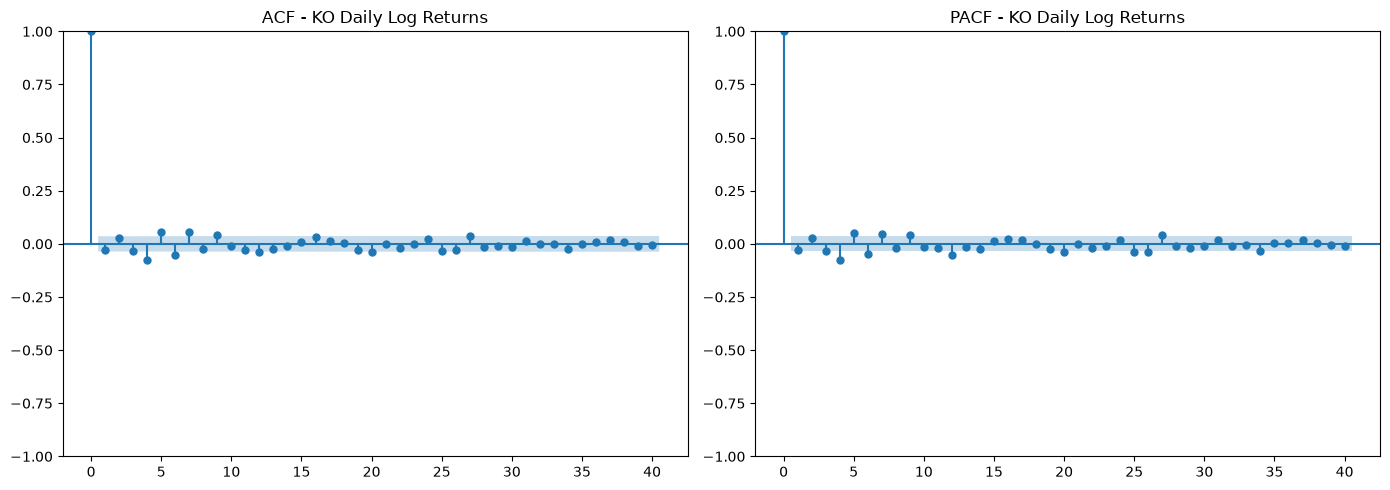

In [4]:
# ACF and PACF plots for daily log returns

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plot_acf(returns, lags=40, ax=axes[0])
axes[0].set_title("ACF - KO Daily Log Returns")

plot_pacf(returns, lags=40, ax=axes[1], method="ywm")
axes[1].set_title("PACF - KO Daily Log Returns")

plt.tight_layout()
plt.show()

### Interpretation of ACF and PACF Plots

The ACF and PACF plots were examined to identify autocorrelation patterns in Coca-Cola daily log returns.

Most autocorrelation values are close to zero, indicating relatively weak linear relationships between daily returns and their previous values.

However, several isolated spikes extend beyond the blue confidence bands, suggesting statistically significant autocorrelation at some individual lags.

There is no strong, gradual decay pattern across the 40 lags examined.

Overall, the plots suggest that KO daily log returns have relatively weak autocorrelation, although some individual lags show statistically detectable relationships.

These findings are useful when considering the choice of forecasting models.

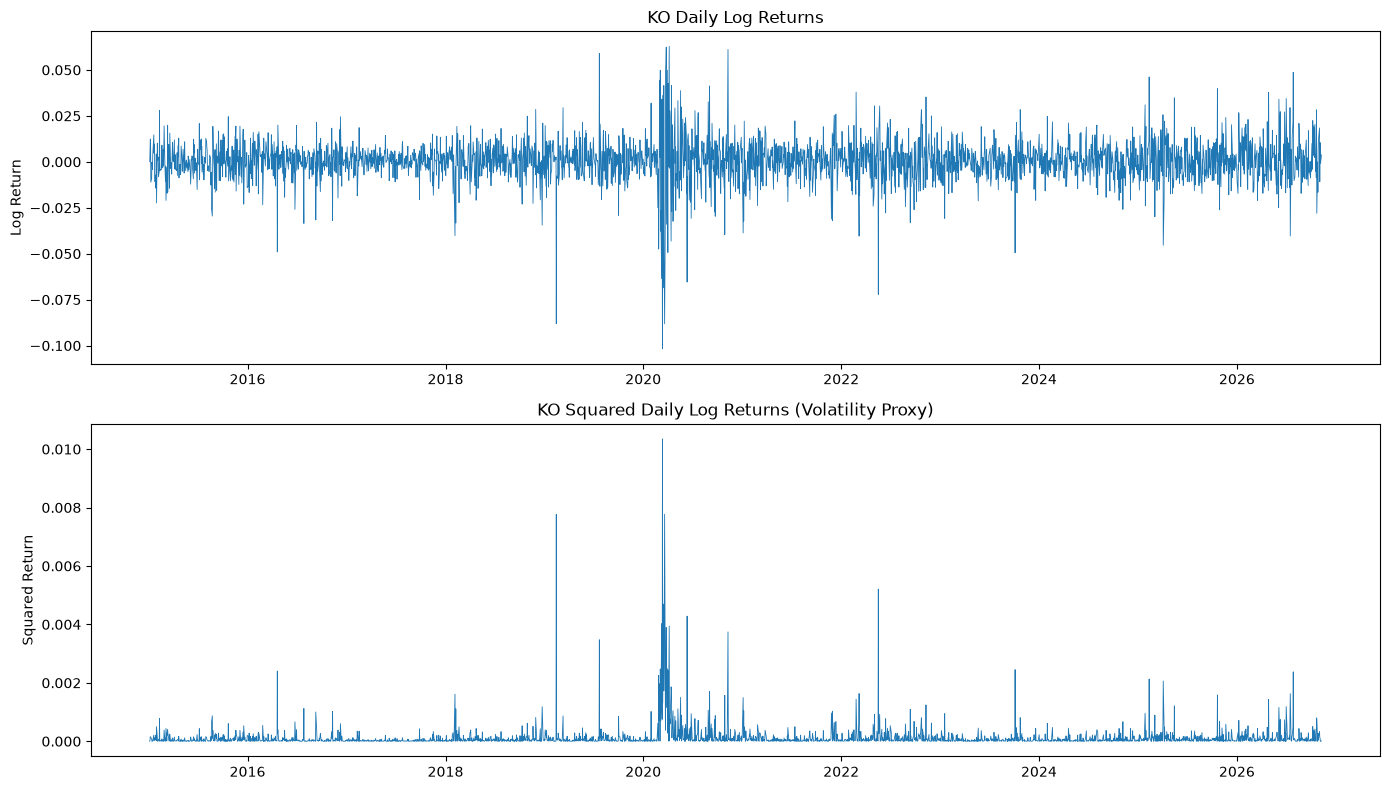

In [5]:
# Plot daily log returns and squared daily log returns

fig, axes = plt.subplots(2, 1, figsize=(14, 8))

axes[0].plot(returns.index, returns, linewidth=0.6)
axes[0].set_title("KO Daily Log Returns")
axes[0].set_ylabel("Log Return")

axes[1].plot(returns.index, returns ** 2, linewidth=0.6)
axes[1].set_title("KO Squared Daily Log Returns (Volatility Proxy)")
axes[1].set_ylabel("Squared Return")

plt.tight_layout()
plt.show()

## 5. Volatility Clustering Analysis

### 5.1 KO Daily Log Returns

The top chart displays Coca-Cola's daily log returns, showing the day-to-day changes in its stock price.

- **Fluctuations around zero:** Returns move above and below the zero line, indicating both positive and negative daily price movements.
- **COVID-19 market shock:** A particularly large negative return appears around early 2020, followed by sharp positive movements. This reflects the period of significant market turbulence during the pandemic.
- **Other large movements:** Additional positive and negative spikes appear at other points in the historical period, indicating occasional unusually large daily price changes.

### 5.2 KO Squared Daily Log Returns

The bottom chart displays squared daily log returns. Squaring removes negative signs and gives greater weight to larger movements, making it a useful proxy for examining volatility.

- **Volatility clustering:** Large spikes appear in groups rather than being evenly distributed. Periods of high volatility tend to be followed by other periods of high volatility.
- **Calmer periods:** Some periods have relatively small squared returns, suggesting lower daily price variability.
- **Market stress:** The large spikes around 2020 highlight periods of particularly high market turbulence.

### 5.3 Overall Interpretation

Together, these charts provide visual evidence that KO returns exhibit time-varying volatility rather than constant volatility.

This phenomenon is known as volatility clustering. It is important in financial forecasting because models that assume constant variance may not adequately capture changing market risk.

Models such as Generalised Autoregressive Conditional Heteroskedasticity (GARCH) can be used to model changing conditional variance over time.

## 6. Why GARCH Models Are Useful

Financial returns often exhibit volatility clustering, where periods of large price movements are followed by other large movements, and periods of smaller movements are followed by calmer periods.

A standard forecasting model may assume that the variance of errors is constant over time. However, financial market volatility changes over time.

The Generalised Autoregressive Conditional Heteroskedasticity (GARCH) model addresses this by modelling conditional variance.

A basic GARCH(1,1) model is:

\[
\sigma_t^2 = \omega + \alpha \epsilon_{t-1}^2 + \beta \sigma_{t-1}^2
\]

Where:

- \(\sigma_t^2\): Current conditional variance.
- \(\omega\): Constant variance component.
- \(\alpha\): Effect of the previous period's squared shock.
- \(\epsilon_{t-1}^2\): Previous period's squared error.
- \(\beta\): Effect of previous conditional variance.

### Conclusion

The volatility clustering observed in KO daily returns suggests that GARCH-type models may be useful for modelling changing market risk.

GARCH focuses on forecasting volatility rather than directly forecasting the stock's closing price.